# Ames Housing: Small Group Regression Competition

**Goal:** predict `SalePrice` for houses in Ames, Iowa. Kaggle ranks submissions by **RMSE**.

**Our approach, in short**
1. Explore the data (the target is skewed, lots of columns have missing values).
2. Clean and engineer features using the data dictionary.
3. Compare a few models using a train/validation split and cross-validation.
4. Tune the best one (Ridge regression on `log(SalePrice)`) with `GridSearchCV`.
5. Refit on all the training data and make the Kaggle submission.

All decisions are made using **only `train.csv`**. `test.csv` has no `SalePrice`, so it is only used at the very end to make predictions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

## 1. Load the data

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print('train:', train.shape)
print('test: ', test.shape)
print('columns only in train:', set(train.columns) - set(test.columns))
train.head()

train: (1200, 81)
test:  (260, 80)
columns only in train: {'SalePrice'}


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


The training data has 1,200 houses and 80 features plus the target. The test data has 260 houses and the same features, but **no `SalePrice`**, since that is what we have to predict.

## 2. Explore the data

### 2a. The target: `SalePrice`

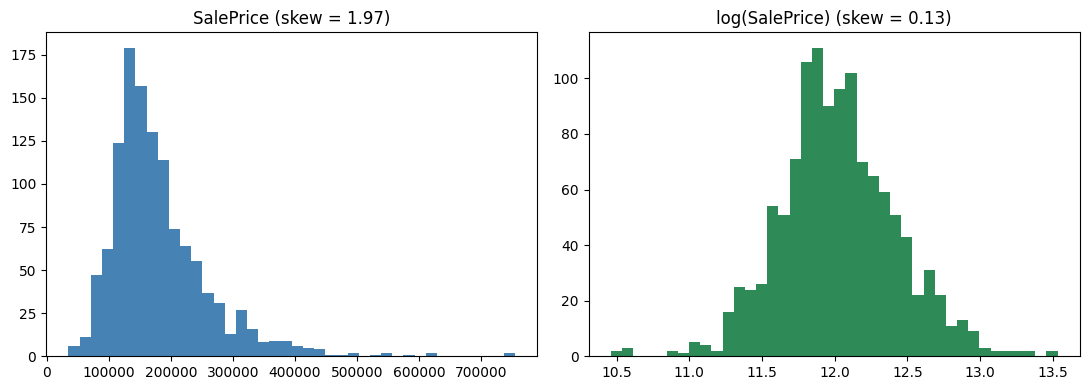

In [3]:
fig, axes = plt.subplots(1, 2, figsize = (11, 4))

axes[0].hist(train['SalePrice'], bins = 40, color = 'steelblue')
axes[0].set_title(f"SalePrice (skew = {train['SalePrice'].skew():.2f})")

axes[1].hist(np.log(train['SalePrice']), bins = 40, color = 'seagreen')
axes[1].set_title(f"log(SalePrice) (skew = {np.log(train['SalePrice']).skew():.2f})")

plt.tight_layout()
plt.show()

`SalePrice` is **right-skewed**: most houses are cheap-ish and a few are very expensive. After taking the log the distribution is much more symmetric.

Why this matters for linear regression: with the raw price, a few expensive houses dominate the fit, and the model implicitly assumes each extra square foot adds the same *dollars* everywhere. With `log(price)`, features change the price by a *percentage* (a better description of housing). So we will **fit the model on `log(SalePrice)`** and convert predictions back to dollars with `exp`.

### 2b. Which features are most related to price?

In [4]:
correlations = train.corr(numeric_only = True)['SalePrice'].sort_values(ascending = False)
print(correlations.head(11).round(3))

SalePrice       1.000
OverallQual     0.789
GrLivArea       0.740
TotalBsmtSF     0.642
GarageCars      0.641
GarageArea      0.623
1stFlrSF        0.619
FullBath        0.572
TotRmsAbvGrd    0.559
YearBuilt       0.523
YearRemodAdd    0.510
Name: SalePrice, dtype: float64


Overall quality (`OverallQual`) and living area (`GrLivArea`) are the strongest, followed by basement size, garage size and year built. These are good things to make sure the model uses well.

### 2c. Missing values

In [5]:
missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending = False)
print(missing)

PoolQC          1196
MiscFeature     1153
Alley           1125
Fence            973
MasVnrType       717
FireplaceQu      564
LotFrontage      210
GarageType        67
GarageFinish      67
GarageQual        67
GarageYrBlt       67
GarageCond        67
BsmtFinType2      33
BsmtExposure      33
BsmtCond          32
BsmtFinType1      32
BsmtQual          32
MasVnrArea         6
dtype: int64


Most of these are **not really missing**. According to the data dictionary, `NA` in columns like `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, `GarageType`, and the `Bsmt...` columns means *the house doesn't have that feature* (no pool, no alley, no garage, no basement...). So:
- For the categorical columns, "missing" is treated as its own category: `'None'`.
- For the quality columns that we convert to numbers (next section), missing becomes `0` (no feature).
- The few truly missing numeric values (like `LotFrontage`) are filled with the median.

### 2d. Outliers

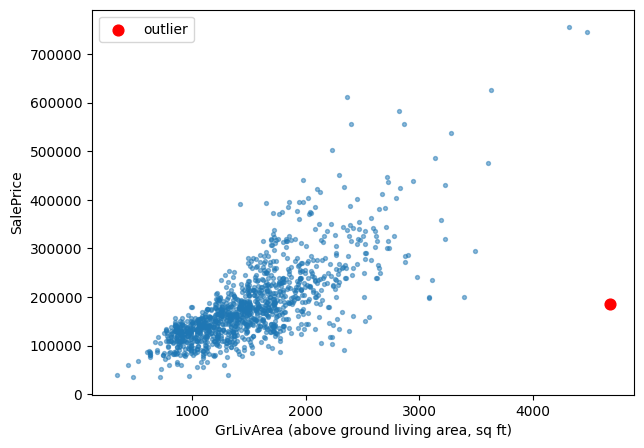

,GrLivArea,SalePrice,SaleCondition,OverallQual
523,4676,184750,Partial,10


In [6]:
plt.figure(figsize = (7, 5))
plt.scatter(train['GrLivArea'], train['SalePrice'], s = 8, alpha = 0.5)

outlier = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
plt.scatter(train.loc[outlier, 'GrLivArea'], train.loc[outlier, 'SalePrice'], color = 'red', s = 60, label = 'outlier')

plt.xlabel('GrLivArea (above ground living area, sq ft)')
plt.ylabel('SalePrice')
plt.legend()
plt.show()

train.loc[outlier, ['GrLivArea', 'SalePrice', 'SaleCondition', 'OverallQual']]

One house has a huge living area (4,676 sq ft) but sold for only about $185k. It was a `Partial` sale (the home was not completed when assessed), so its price doesn't reflect its size. The other very large houses follow the normal trend. Because linear regression is sensitive to points like this, we **remove this one house from the training data**.

In [7]:
train = train[~outlier].reset_index(drop = True)
print('training rows after removing the outlier:', len(train))

training rows after removing the outlier: 1199


## 3. Feature engineering

We use the data dictionary to turn the data into something a regression model can use well. All of the steps below only use information in each row (not the target), so we can apply the exact same function to both the train and test data.

1. **Quality ratings → numbers.** Columns like `ExterQual` use `Ex / Gd / TA / Fa / Po`. These are *ordered*, so we map them to 5, 4, 3, 2, 1 (and 0 for "no such feature"). This keeps the order, which one hot encoding would throw away.
2. **New combined features**, such as total square footage, total bathrooms, and age of the house when it sold.
3. **`MSSubClass`** is stored as a number but is really a *category* (20 = 1-story 1946 & newer, 60 = 2-story...), so we convert it to text so it gets one hot encoded.
4. Drop `Id` (just a label) and `GarageYrBlt` (mostly duplicates `YearBuilt` and has missing values).

In [8]:
quality_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1}    # NA -> 0 (feature not present)

def prepare(df):
    d = df.copy()

    # 1. ordered quality ratings -> numbers
    for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
                'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']:
        d[col] = d[col].map(quality_map).fillna(0)
    d['BsmtExposure'] = d['BsmtExposure'].map({'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1}).fillna(0)
    for col in ['BsmtFinType1', 'BsmtFinType2']:
        d[col] = d[col].map({'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1}).fillna(0)
    d['GarageFinish'] = d['GarageFinish'].map({'Fin': 3, 'RFn': 2, 'Unf': 1}).fillna(0)
    d['PavedDrive'] = d['PavedDrive'].map({'Y': 2, 'P': 1, 'N': 0})
    d['CentralAir'] = (d['CentralAir'] == 'Y').astype(int)

    # 2. new features built from existing ones
    d['TotalSF'] = d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF']
    d['TotalBath'] = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    d['HouseAge'] = (d['YrSold'] - d['YearBuilt']).clip(lower = 0)
    d['RemodAge'] = (d['YrSold'] - d['YearRemodAdd']).clip(lower = 0)
    d['Remodeled'] = (d['YearRemodAdd'] != d['YearBuilt']).astype(int)
    d['TotalPorchSF'] = d['OpenPorchSF'] + d['EnclosedPorch'] + d['3SsnPorch'] + d['ScreenPorch'] + d['WoodDeckSF']
    d['HasGarage'] = (d['GarageArea'] > 0).astype(int)
    d['HasBasement'] = (d['TotalBsmtSF'] > 0).astype(int)
    d['HasFireplace'] = (d['Fireplaces'] > 0).astype(int)
    d['HasPool'] = (d['PoolArea'] > 0).astype(int)
    d['NewHouse'] = (d['SaleType'] == 'New').astype(int)

    # 3. MSSubClass is really a category
    d['MSSubClass'] = d['MSSubClass'].astype(str)

    # 4. drop columns we don't want as features
    d = d.drop(columns = ['Id', 'GarageYrBlt'])
    if 'SalePrice' in d.columns:
        d = d.drop(columns = ['SalePrice'])
    return d

X = prepare(train)
y = train['SalePrice']
X_test = prepare(test)

print('features:', X.shape[1])
print('same columns in train and test:', list(X.columns) == list(X_test.columns))

features: 89
same columns in train and test: True


## 4. Train / validation split and baseline

As in class, we hold out part of the training data so we can see how the model does on houses it has **not** seen. (We call it the *validation* set, since the real test set is on Kaggle.)

- **Train RMSE:** error on the houses the model learned from.
- **Validation RMSE:** error on held-out houses. This is the honest number, and it's what we compare to the baseline.

The baseline is "predict the average price for every house".

In [9]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size = 0.2, random_state = 42)
print(X_train.shape, X_valid.shape)

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

baseline_rmse = rmse(y_valid, np.full(len(y_valid), y_train.mean()))
print(f'Baseline validation RMSE: ${baseline_rmse:,.0f}')

(959, 89) (240, 89)
Baseline validation RMSE: $73,641


## 5. Build the preprocessing pipeline

Same idea as the `make_column_transformer` + `Pipeline` pattern from class, with a few extra steps:

- **Numeric columns:** fill any missing values with the median, then standardize with `StandardScaler`. Scaling matters because Ridge regression penalizes large coefficients, and the penalty is only fair if the features are on the same scale. It also lets us compare coefficients later.
- **Categorical columns:** fill missing values with `'None'`, then `OneHotEncoder`. `handle_unknown = 'ignore'` makes sure a category that only appears in the test data doesn't crash the model.

In [10]:
numeric_cols = X.select_dtypes(include = 'number').columns.tolist()
categorical_cols = X.select_dtypes(exclude = 'number').columns.tolist()
print(len(numeric_cols), 'numeric columns,', len(categorical_cols), 'categorical columns')

numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy = 'median')),
    ('scale', StandardScaler())
])
categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy = 'constant', fill_value = 'None')),
    ('onehot', OneHotEncoder(handle_unknown = 'ignore'))
])

preprocessor = make_column_transformer(
    (numeric_pipe, numeric_cols),
    (categorical_pipe, categorical_cols)
)

def build_model(estimator, log_target = True):
    # preprocessing step + model step in a pipeline
    pipe = Pipeline([('prep', clone(preprocessor)), ('model', estimator)])
    if log_target:
        # fit on log(price) and convert predictions back to dollars automatically
        return TransformedTargetRegressor(pipe, func = np.log, inverse_func = np.exp)
    return pipe

61 numeric columns, 28 categorical columns


## 6. Compare models

We start simple and add complexity step by step. For each model we report train RMSE, validation RMSE, and a 5-fold cross-validation RMSE computed **inside the training part** (a more stable estimate, so we use it to choose between models).

1. **Simple regression:** one numeric feature (`GrLivArea`).
2. **Multiple regression** with all features, on raw price.
3. The same, but predicting **log price**.
4. **Ridge** and **Lasso** (regularized regression) on log price.
5. A tree-based model (**gradient boosting**) for comparison.

In [11]:
kf = KFold(n_splits = 5, shuffle = True, random_state = 0)
results = []

def evaluate(name, model, cols = None):
    # cols lets us use only some columns (for the simple model)
    Xtr = X_train if cols is None else X_train[cols]
    Xva = X_valid if cols is None else X_valid[cols]
    model.fit(Xtr, y_train)
    train_rmse = rmse(y_train, model.predict(Xtr))
    valid_rmse = rmse(y_valid, model.predict(Xva))
    cv_rmse = -cross_val_score(model, Xtr, y_train, cv = kf, scoring = 'neg_root_mean_squared_error').mean()
    results.append({'model': name, 'train RMSE': train_rmse, 'validation RMSE': valid_rmse, 'CV RMSE': cv_rmse})
    print(f'{name:45s} train ${train_rmse:>8,.0f} | validation ${valid_rmse:>8,.0f} | CV ${cv_rmse:>8,.0f}')

# 1. simple regression: one numeric feature
evaluate('1. Simple: GrLivArea only', LinearRegression(), cols = ['GrLivArea'])

# 2. all features, raw price
evaluate('2. All features (raw price)', build_model(LinearRegression(), log_target = False))

# 3. all features, log price
evaluate('3. All features (log price)', build_model(LinearRegression()))

# 4. regularized models on log price
evaluate('4a. Ridge (alpha = 20, log price)', build_model(Ridge(alpha = 20)))
evaluate('4b. Lasso (alpha = 0.001, log price)', build_model(Lasso(alpha = 0.001, max_iter = 50000)))

# 5. tree-based model for comparison
evaluate('5. Gradient boosting (log price)', build_model(GradientBoostingRegressor(n_estimators = 400, learning_rate = 0.05,
                                                                                    max_depth = 3, subsample = 0.8, random_state = 0)))

1. Simple: GrLivArea only                     train $  54,475 | validation $  49,127 | CV $  54,496


2. All features (raw price)                   train $  20,033 | validation $  26,844 | CV $  32,040


3. All features (log price)                   train $  15,608 | validation $  22,276 | CV $  23,307


4a. Ridge (alpha = 20, log price)             train $  17,268 | validation $  20,693 | CV $  21,200


4b. Lasso (alpha = 0.001, log price)          train $  18,178 | validation $  20,356 | CV $  20,987


5. Gradient boosting (log price)              train $   9,143 | validation $  19,151 | CV $  24,771


**What this tells us**

- The baseline (predict the average price for everyone) has a validation RMSE of about $74k. Even one feature (`GrLivArea`) cuts that a lot, and using all of the features cuts it much more.
- **Plain linear regression overfits:** with roughly 250 columns (most of them one hot columns) and only about 950 training houses, its train RMSE is far below its validation RMSE.
- **Predicting `log(price)`** helps a lot compared with raw price.
- **Ridge and Lasso** shrink the coefficients, which reduces overfitting: the gap between train and validation RMSE gets smaller and the CV RMSE improves.
- **Gradient boosting** has the lowest validation RMSE on this one split, but its train RMSE is much lower still (it overfits) and its cross-validation RMSE is clearly *worse* than Ridge/Lasso. The validation set is only 240 houses, so a few expensive houses can swing it. Cross-validation uses every house, so we trust CV more, and the linear models are also easier to interpret.

Ridge and Lasso are essentially tied. We go with **Ridge** because it keeps all the features (Lasso drops many of them) and tends to be more stable. Next we tune its penalty strength, `alpha`.

## 7. Tune Ridge with `GridSearchCV`

`alpha` controls how strongly large coefficients are penalized: too small and the model overfits, too large and it underfits. We let `GridSearchCV` try several values using 5-fold cross-validation on the training part only.

(The parameter name is `regressor__model__alpha` because `alpha` lives inside the `model` step of the pipeline, which is inside the `TransformedTargetRegressor`.)

In [12]:
param_grid = {'regressor__model__alpha': [1, 3, 10, 20, 30, 50, 100, 200]}

grid = GridSearchCV(build_model(Ridge()), param_grid, cv = kf, scoring = 'neg_root_mean_squared_error')
grid.fit(X_train, y_train)

cv_results = pd.DataFrame({
    'alpha': param_grid['regressor__model__alpha'],
    'CV RMSE': -grid.cv_results_['mean_test_score']
})
print(cv_results.round(0).to_string(index = False))

best_alpha = grid.best_params_['regressor__model__alpha']
print('\nBest alpha:', best_alpha)

tuned_ridge = grid.best_estimator_
print(f"Tuned Ridge: train RMSE ${rmse(y_train, tuned_ridge.predict(X_train)):,.0f} | validation RMSE ${rmse(y_valid, tuned_ridge.predict(X_valid)):,.0f}")

 alpha  CV RMSE
     1  22032.0
     3  21601.0
    10  21215.0
    20  21200.0
    30  21271.0
    50  21452.0
   100  21910.0
   200  22768.0

Best alpha: 20
Tuned Ridge: train RMSE $17,268 | validation RMSE $20,693


## 8. Things we tried that did not help

**Polynomial features.** Maybe the most important features have curved effects. We added squares and interactions of eight key features (`OverallQual`, `GrLivArea`, `TotalSF`, ...) using `PolynomialFeatures`, then compared cross-validation RMSE with the model without them.

In [13]:
top_features = ['OverallQual', 'GrLivArea', 'TotalSF', 'GarageCars', 'TotalBath', 'HouseAge', 'ExterQual', 'KitchenQual']

poly_pipe = Pipeline([
    ('impute', SimpleImputer(strategy = 'median')),
    ('scale', StandardScaler()),
    ('poly', PolynomialFeatures(degree = 2, include_bias = False)),
    ('scale2', StandardScaler())
])
preprocessor_poly = make_column_transformer(
    (numeric_pipe, numeric_cols),
    (categorical_pipe, categorical_cols),
    (poly_pipe, top_features)
)
ridge_poly = TransformedTargetRegressor(
    Pipeline([('prep', preprocessor_poly), ('model', Ridge(alpha = 100))]),
    func = np.log, inverse_func = np.exp)

cv_poly = -cross_val_score(ridge_poly, X_train, y_train, cv = kf, scoring = 'neg_root_mean_squared_error').mean()
cv_plain = -grid.best_score_
print(f'Ridge without polynomial features: CV RMSE ${cv_plain:,.0f}')
print(f'Ridge with polynomial features:    CV RMSE ${cv_poly:,.0f}')

Ridge without polynomial features: CV RMSE $21,200
Ridge with polynomial features:    CV RMSE $22,362


The polynomial features did **not** improve cross-validation RMSE (they add many extra columns for a small dataset, which increases overfitting), so we leave them out. The same thing happened when we tried log-transforming the size columns. Sometimes simpler is better.

## 9. Where does the model make mistakes?

We look at validation predictions versus the actual prices, and the houses with the largest errors.

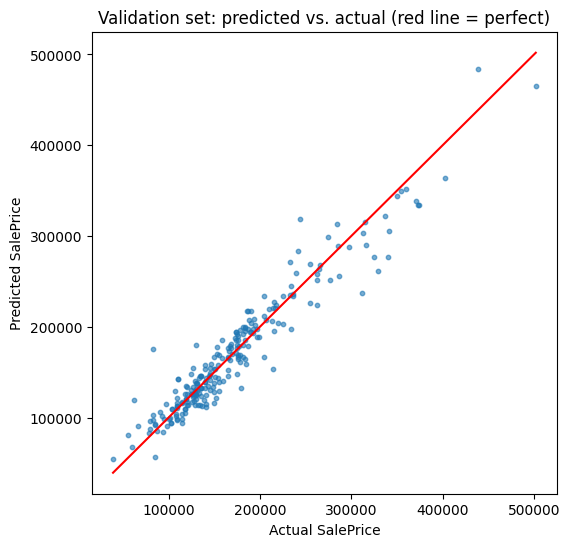

,actual,predicted,error,Neighborhood,OverallQual,GrLivArea,SaleCondition
631,82500,176033.0,93533.0,NWAmes,7,1411,Family
218,311500,237093.0,-74407.0,Crawfor,7,1954,Normal
70,244000,318316.0,74316.0,NAmes,7,2223,Normal
884,328900,261261.0,-67639.0,Somerst,9,1709,Abnorml
377,340000,276651.0,-63349.0,Somerst,8,2466,Normal
328,214500,153025.0,-61475.0,BrkSide,6,2134,Normal
462,62383,119582.0,57199.0,Sawyer,5,864,Normal
713,130500,180269.0,49769.0,Sawyer,6,1479,Normal


In [14]:
valid_pred = tuned_ridge.predict(X_valid)

plt.figure(figsize = (6, 6))
plt.scatter(y_valid, valid_pred, s = 10, alpha = 0.6)
lims = [y_valid.min(), y_valid.max()]
plt.plot(lims, lims, color = 'red')
plt.xlabel('Actual SalePrice')
plt.ylabel('Predicted SalePrice')
plt.title('Validation set: predicted vs. actual (red line = perfect)')
plt.show()

errors = pd.DataFrame({
    'actual': y_valid,
    'predicted': valid_pred.round(0),
    'error': (valid_pred - y_valid).round(0),
    'Neighborhood': X_valid['Neighborhood'],
    'OverallQual': X_valid['OverallQual'],
    'GrLivArea': X_valid['GrLivArea'],
    'SaleCondition': X_valid['SaleCondition']
})
errors.reindex(errors['error'].abs().sort_values(ascending = False).index).head(8)

The predictions follow the red line fairly closely. Some of the biggest misses are houses whose price is unusual for what they are. For example, the worst miss is a `Family` sale (a sale between family members, which often happens below market price), and some higher-end houses in newer neighborhoods like Somerset were under-predicted. Things like the relationship between buyer and seller, the interior condition, and negotiation aren't in the data, so no model using only these features can get them right.

## 10. Which features matter most?

Because we standardized the numeric features, their coefficients are on the same scale and can be compared directly. The model predicts `log(price)`, so a coefficient of 0.05 means roughly "a +5% change in price for a one standard deviation increase in that feature, holding the others fixed". (Remember that correlated features share credit, so individual coefficients shouldn't be over-interpreted.)

In [15]:
ridge_pipeline = tuned_ridge.regressor_                      # the fitted pipeline inside the wrapper
feature_names = ridge_pipeline.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(ridge_pipeline.named_steps['model'].coef_, index = feature_names)
coefs.index = [name.split('__')[-1] for name in coefs.index]    # shorter names

print('Biggest positive effects (approx. % change in price per +1 std dev):')
print((coefs.sort_values(ascending = False).head(10) * 100).round(1).to_string())
print('\nBiggest negative effects:')
print((coefs.sort_values().head(10) * 100).round(1).to_string())

Biggest positive effects (approx. % change in price per +1 std dev):
OverallQual             7.4
Neighborhood_Crawfor    6.0
Functional_Typ          5.7
GrLivArea               4.9
MSZoning_RL             4.8
TotalSF                 4.4
OverallCond             4.4
Neighborhood_StoneBr    4.3
Condition1_Norm         4.0
Exterior1st_BrkFace     3.5

Biggest negative effects:
MSZoning_C (all)        -8.4
SaleCondition_Abnorml   -4.3
Neighborhood_IDOTRR     -3.7
Functional_Maj2         -3.4
Exterior1st_Wd Sdng     -3.3
Neighborhood_MeadowV    -3.1
MSSubClass_160          -3.0
MasVnrType_BrkCmn       -2.6
Neighborhood_Gilbert    -2.6
Neighborhood_Edwards    -2.5


## 11. Final model and Kaggle submission

We refit the tuned Ridge model on **all** of the training data (train + validation) so it learns from as many houses as possible, then predict the test houses.

In [16]:
final_model = build_model(Ridge(alpha = best_alpha))
final_model.fit(X, y)

test_predictions = final_model.predict(X_test)

# sanity check: are all of the predictions reasonable?
largest = pd.Series(test_predictions, index = test['Id']).sort_values(ascending = False).head(5)
print('Most expensive predictions:')
print(largest.round(0).to_string())
print(f"\nMost expensive house in the training data: ${y.max():,.0f}")

Most expensive predictions:
Id
1299    2812056.0
1374     482143.0
1244     440131.0
1354     419891.0
1269     418815.0

Most expensive house in the training data: $755,000


**Problem:** one house is predicted at over $2.8 million, but the most expensive house in the training data sold for $755,000. A linear model extrapolates in a straight line, so if a test house is bigger than anything it has seen, the prediction can explode. Let's check whether any test houses are outside the range of the training data.

In [17]:
# range of each numeric feature in the training data
lowest = X[numeric_cols].min()
highest = X[numeric_cols].max()

outside = ((X_test[numeric_cols] < lowest) | (X_test[numeric_cols] > highest)).any(axis = 1)
print(outside.sum(), 'test houses have at least one numeric feature outside the training range:')

compare = X_test.loc[outside, ['GrLivArea', 'TotalSF', 'LotArea', 'TotalBsmtSF', 'OverallQual']].copy()
compare.insert(0, 'Id', test.loc[outside, 'Id'])
print(compare.to_string(index = False))
print('\nlargest value of each of these in the training data:')
print(X[['GrLivArea', 'TotalSF', 'LotArea', 'TotalBsmtSF']].max().to_string())

5 test houses have at least one numeric feature outside the training range:
  Id  GrLivArea  TotalSF  LotArea  TotalBsmtSF  OverallQual
1299       5642    11752    63887         6110           10
1329       2792     4302    10440         1510            6
1350       2358     2837     5250          684            8
1387       2784     4176    16692         1392            7
1424       2201     2898    19690          697            6

largest value of each of these in the training data:
GrLivArea        4476
TotalSF          6872
LotArea        215245
TotalBsmtSF      3206


House 1299 is far bigger than any house in the training data (5,642 sq ft of living area vs. a training maximum of 4,476, and a huge lot and basement). We have no examples like it, so the model's prediction for it is just a guess from extrapolation. We add two simple safeguards, both based only on the training data:

1. **Clip** each numeric feature of the test houses to the range seen in training, so the model never has to extrapolate.
2. **Cap** the final predictions at the lowest and highest prices seen in training.

The other test houses are essentially unaffected.

In [18]:
# 1. clip test features to the training range
X_test_clipped = X_test.copy()
X_test_clipped[numeric_cols] = X_test[numeric_cols].clip(lower = lowest, upper = highest, axis = 1)

# 2. predict, then cap the predictions at the training price range
test_predictions = final_model.predict(X_test_clipped)
test_predictions = np.clip(test_predictions, y.min(), y.max())

# the sample submission uses Ids 0, 1, 2, ... in the same order as the test rows
submission = pd.DataFrame({'Id': np.arange(len(test)), 'SalePrice': test_predictions})
submission.to_csv('submission.csv', index = False)

# sanity checks before uploading
print('rows:', len(submission), '(test has', len(test), 'houses)')
print('missing predictions:', submission['SalePrice'].isna().sum())
print('smallest / largest prediction:', f"${submission['SalePrice'].min():,.0f} / ${submission['SalePrice'].max():,.0f}")
submission.head()

rows: 260 (test has 260 houses)
missing predictions: 0
smallest / largest prediction: $64,806 / $755,000


,Id,SalePrice
0,0,98088.250035
1,1,197269.849080
2,2,131427.735625
3,3,198770.022758
4,4,147396.704677


## 12. Summary and reflection

**Final model:** Ridge regression on `log(SalePrice)`, with ordinal quality ratings converted to numbers, a few new combined features (total square feet, total bathrooms, house age, ...), median imputation + scaling for numeric columns, and one hot encoding for categorical columns. `alpha` was chosen with `GridSearchCV`.

**What helped the most**
- Predicting `log(price)` instead of raw price.
- Regularization (Ridge/Lasso) instead of plain linear regression with so many columns.
- Treating missing values according to the data dictionary ("NA" usually means "no such feature").
- Removing one clearly unrepresentative outlier from the training data.
- Guarding against extrapolation (clipping features and capping predictions) for a test house much bigger than anything in the training data.

**What didn't help:** polynomial features and log-transforming the size features did not improve cross-validation RMSE.

**Limitations and next steps**
- Linear models extrapolate, so extremely large or unusual houses may be predicted poorly. Our clipping and capping helps, but a house far outside the training data is still a guess.
- With more time we could try combining models (for example Ridge plus gradient boosting), or create more features from `Neighborhood` and sale conditions.
- Validation RMSE is an estimate: a different split would give a slightly different number, so tiny differences between models aren't meaningful.